In [21]:
import pandas as pd
import matplotlib.pyplot as plt

Matplotlib is building the font cache; this may take a moment.


In [22]:
cy = pd.read_csv(r"C:\Users\PC\Downloads\crop_yield.csv")

In [10]:
cy.info()

<class 'pandas.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   FARM_ID          3000 non-null   str    
 1   CROP_TYPE        3000 non-null   str    
 2   YIELD_KG         2670 non-null   float64
 3   AREA_ACRES       2856 non-null   float64
 4   HARVEST_DATE     3000 non-null   str    
 5   DISTRICT         2874 non-null   str    
 6   SEASON           3000 non-null   str    
 7   FERTILIZER_USED  2682 non-null   str    
 8   YIELD_VALUE      3000 non-null   int64  
dtypes: float64(2), int64(1), str(6)
memory usage: 312.8 KB


In [13]:
cy.head(10)

,FARM_ID,CROP_TYPE,YIELD_KG,AREA_ACRES,HARVEST_DATE,DISTRICT,SEASON,FERTILIZER_USED,YIELD_VALUE
0,F001,Wheat,1500.0,4.0,01/01/2023,Sialkot,Rabi,Yes,30000
1,F002,Wheat,1500.0,5.0,02/01/2023,Multan,Rabi,No,30000
2,F003,Wheat,2500.0,5.0,03/01/2023,Faisalabad,Rabi,Yes,50000
3,F004,Wheat,1500.0,NaN,04/01/2023,Multan,Rabi,Yes,30000
4,F005,Rice,1500.0,4.0,05/01/2023,Faisalabad,Rabi,No,30000
5,F006,Rice,2000.0,6.0,06/01/2023,Faisalabad,Rabi,Yes,40000
6,F007,Maize,1500.0,6.0,07/01/2023,Faisalabad,Rabi,No,30000
7,F008,Wheat,1500.0,5.0,08/01/2023,Lahore,Rabi,No,30000
8,F009,Wheat,2000.0,5.0,09/01/2023,Faisalabad,Rabi,Yes,40000
9,F010,Wheat,1500.0,3.0,10/01/2023,Faisalabad,Rabi,Yes,30000


In [14]:
cy.isnull().sum()

FARM_ID              0
CROP_TYPE            0
YIELD_KG           330
AREA_ACRES         144
HARVEST_DATE         0
DISTRICT           126
SEASON               0
FERTILIZER_USED    318
YIELD_VALUE          0
dtype: int64

In [15]:
cy.dtypes

FARM_ID                str
CROP_TYPE              str
YIELD_KG           float64
AREA_ACRES         float64
HARVEST_DATE           str
DISTRICT               str
SEASON                 str
FERTILIZER_USED        str
YIELD_VALUE          int64
dtype: object

In [16]:
cy.describe()

,YIELD_KG,AREA_ACRES,YIELD_VALUE
count,2670.000000,2856.000000,3000.000000
mean,2014.232210,4.420168,39657.780000
std,407.846962,0.979259,8405.078755
min,1500.000000,3.000000,20068.000000
25%,1500.000000,4.000000,30000.000000
50%,2000.000000,4.000000,40000.000000
75%,2500.000000,5.000000,50000.000000
max,2500.000000,6.000000,50000.000000


In [20]:
cy.describe(include="object")

C:\Users\PC\AppData\Local\Temp\ipykernel_11788\1539194765.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cy.describe(include="object")


,FARM_ID,CROP_TYPE,HARVEST_DATE,DISTRICT,SEASON,FERTILIZER_USED
count,3000,3000,3000,2874,3000,2682
unique,3000,4,3000,4,2,2
top,F001,Wheat,01/01/2023,Faisalabad,Rabi,Yes
freq,1,1158,1,936,1528,1776


In [24]:
cy.dropna(subset=["YIELD_KG"])

,FARM_ID,CROP_TYPE,YIELD_KG,AREA_ACRES,HARVEST_DATE,DISTRICT,SEASON,FERTILIZER_USED,YIELD_VALUE
0,F001,Wheat,1500.0,4.0,01/01/2023,Sialkot,Rabi,Yes,30000
1,F002,Wheat,1500.0,5.0,02/01/2023,Multan,Rabi,No,30000
2,F003,Wheat,2500.0,5.0,03/01/2023,Faisalabad,Rabi,Yes,50000
3,F004,Wheat,1500.0,NaN,04/01/2023,Multan,Rabi,Yes,30000
4,F005,Rice,1500.0,4.0,05/01/2023,Faisalabad,Rabi,No,30000
...,...,...,...,...,...,...,...,...,...
2995,F2996,Wheat,1500.0,NaN,15/03/2031,NaN,Rabi,Yes,30000
2996,F2997,Rice,2000.0,3.0,16/03/2031,Lahore,Rabi,Yes,40000
2997,F2998,Sugarcane,2000.0,5.0,17/03/2031,Lahore,Rabi,Yes,40000
2998,F2999,Sugarcane,2000.0,NaN,18/03/2031,Lahore,Rabi,NaN,40000


In [26]:
# 7. Remove all rows where YIELD_KG has missing (NaN) values
cy = cy.dropna(subset=["YIELD_KG"])

# 8. Fill missing values in AREA_ACRES with the mean of that column
cy["AREA_ACRES"] = cy["AREA_ACRES"].fillna(cy["AREA_ACRES"].mean())

# 9. Replace missing values in DISTRICT with 'Unknown'
cy["DISTRICT"] = cy["DISTRICT"].fillna("Unknown")

# 10. Replace missing values in FERTILIZER_USED with 'No'
cy["FERTILIZER_USED"] = cy["FERTILIZER_USED"].fillna("No")

# 11. Replace missing values in YIELD_VALUE with the mean of that column
cy["YIELD_VALUE"] = cy["YIELD_VALUE"].fillna(cy["YIELD_VALUE"].mean())

# 12. Convert HARVEST_DATE to datetime format (handling invalid dates)
cy["HARVEST_DATE"] = pd.to_datetime(
    cy["HARVEST_DATE"], errors="coerce", format="%d/%m/%Y"
)

# 13. Remove 'F' from FARM_ID and convert the result to an integer
cy["FARM_ID"] = cy["FARM_ID"].astype(str).str.replace("F", "", regex=False).astype(int)

# 14. Re-check missing values after cleaning
print(cy.isnull().sum())

# 15. Re-check data types of all columns after cleaning
print(cy.dtypes)

FARM_ID            0
CROP_TYPE          0
YIELD_KG           0
AREA_ACRES         0
HARVEST_DATE       0
DISTRICT           0
SEASON             0
FERTILIZER_USED    0
YIELD_VALUE        0
dtype: int64
FARM_ID                     int64
CROP_TYPE                     str
YIELD_KG                  float64
AREA_ACRES                float64
HARVEST_DATE       datetime64[us]
DISTRICT                      str
SEASON                        str
FERTILIZER_USED               str
YIELD_VALUE                 int64
dtype: object


DATA ANALYSIS AND VISUALIZATION

            YIELD_KG
CROP_TYPE           
Maize      1112500.0
Rice       1638000.0
Sugarcane   592000.0
Wheat      2035500.0


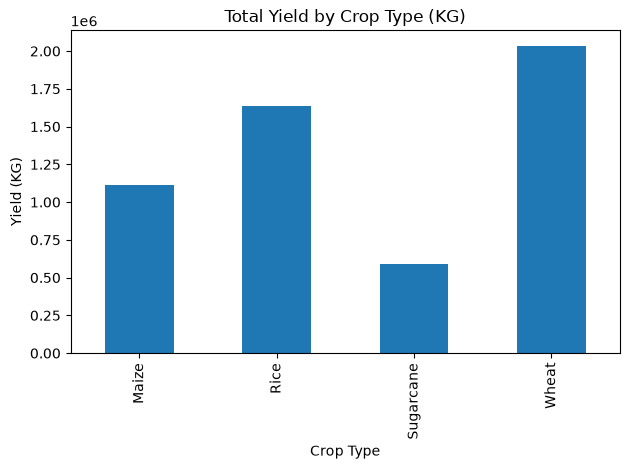

              YIELD_KG
HARVEST_DATE          
2023-01-01      1500.0
2023-01-02      1500.0
2023-01-03      2500.0
2023-01-04      1500.0
2023-01-05      1500.0
...                ...
2031-03-15      1500.0
2031-03-16      2000.0
2031-03-17      2000.0
2031-03-18      2000.0
2031-03-19      2500.0

[2670 rows x 1 columns]


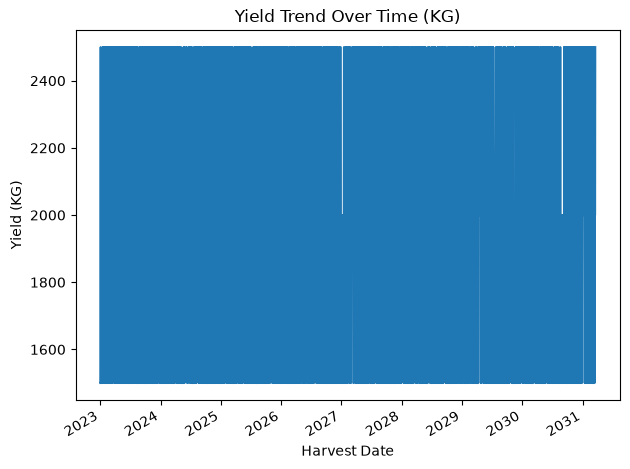

In [28]:
# 16. Group data by CROP_TYPE and calculate total YIELD_KG for each type
crop_yield_summary = cy.groupby("CROP_TYPE").agg({"YIELD_KG": "sum"})
print(crop_yield_summary)

# 17. Plot a bar chart of total YIELD_KG by CROP_TYPE
crop_yield_summary["YIELD_KG"].plot(kind="bar")
plt.title("Total Yield by Crop Type (KG)")
plt.ylabel("Yield (KG)")
plt.xlabel("Crop Type")
plt.tight_layout()
plt.show()

# 18a. Create a pivot table summarizing total YIELD_KG by HARVEST_DATE
yield_pivot = cy.pivot_table(
    values="YIELD_KG", index="HARVEST_DATE", aggfunc="sum"
)
print(yield_pivot)

# 18b. Plot a line chart of the yield trend over time from the pivot table and save it
yield_pivot["YIELD_KG"].plot(kind="line")
plt.title("Yield Trend Over Time (KG)")
plt.ylabel("Yield (KG)")
plt.xlabel("Harvest Date")
plt.tight_layout()
plt.savefig("crop_yield_trend.png")
plt.show()